# ExploreCor Showcases: Using DraCor

> **Authors:** Ingo Börner (University of Potsdam, Germany), <a href="https://orcid.org/0000-0001-8294-2541"><img src="https://orcid.org/assets/vectors/orcid.logo.icon.svg" alt="ORCID iD" width="16" height="16" style="vertical-align: -2px"/> 0000-0001-8294-2541</a>; Peer Trilcke (University of Potsdam, Germany), <a href="https://orcid.org/0000-0002-1421-4320"><img src="https://orcid.org/assets/vectors/orcid.logo.icon.svg" alt="ORCID iD" width="16" height="16" style="vertical-align: -2px"/> 0000-0002-1421-4320</a>
> **Version:** 2 – DraCor API v1, PyDraCor 3 (November 2026); see the version history at the end of the notebook
> **Status:** [![Status on dracor.org](https://img.shields.io/endpoint?url=https%3A%2F%2Fraw.githubusercontent.com%2Fdracor-org%2Fdracor-notebooks%2Fmain%2Fstatus%2Fbadges%2Fexplorecor-showcases.production.json)](https://dracor-org.github.io/dracor-notebooks/appendix/tested-environments.html) [![Status on staging](https://img.shields.io/endpoint?url=https%3A%2F%2Fraw.githubusercontent.com%2Fdracor-org%2Fdracor-notebooks%2Fmain%2Fstatus%2Fbadges%2Fexplorecor-showcases.staging.json)](https://dracor-org.github.io/dracor-notebooks/appendix/tested-environments.html)
> **Tested with:** DraCor API 1.4.1 (production server) and 1.5.0-rc.1 (staging server), PyDraCor 3.0.2, Python 3.10 to 3.12, 2026-11-17

This notebook is material from the CLS INFRA Training School **"ExploreCor: Using Programmable Corpora in Computational Literary Studies"**, held in Vienna in June 2024. The name of the notebook, *ExploreCor Showcases*, refers to this training school. The notebook was used in the opening session, "Introduction to Programmable Corpora", to show what can be done with DraCor as a *Programmable Corpus*. The material of the training school is documented on [DARIAH-Campus](https://campus.dariah.eu/resources/events/explore-cor-using-programmable-corpora-in-computational-literary-studies) and in the repository [dracor-org/dracor-explorecor](https://github.com/dracor-org/dracor-explorecor).

The showcases come from chapter 4, "The DraCor Prototype in Action. Four Showcases", of the CLS INFRA report D7.1 *On Programmable Corpora* (Börner and Trilcke 2023, pp. 14–21). The report describes the workflows; this notebook implements them in Python with the current DraCor API:

1. a one-click download of modelled text data (D7.1, §4.1);
2. extracting stage directions for Natural Language Processing (NLP) (D7.1, §4.3);
3. plotting network measures for thousands of plays (D7.1, §4.4).

The fourth showcase of the report, mapping the locations of first performances with a SPARQL query that links DraCor to Wikidata (D7.1, §4.2), is left out for now.

## Setting up the notebook

Install the required packages with `pip install -r requirements.txt`, or uncomment and run the following cell. Showcase 2 uses the language data of spaCy for German, which comes with the package `spacy`; no model has to be downloaded.

In [1]:
# !pip install "pydracor>=3.0" pandas matplotlib spacy

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pydracor import DraCorAPI
from spacy.lang.de import German

The notebook uses the public DraCor API at [dracor.org](https://dracor.org). To use another DraCor server, e.g. the staging server `https://staging.dracor.org/api/v1`, change `api_base`.

In [3]:
api_base = "https://dracor.org/api/v1"
dracor = DraCorAPI(host=api_base)
dracor.get_info()

Info(name='DraCor API v1', version='1.4.1', status='stable', existdb='6.4.0', base='https://dracor.org/api/v1', openapi='https://dracor.org/api/v1/openapi.yaml')

## Showcase 1: One-click download of modelled text data

*D7.1, §4.1*

When considering an ecosystem for Computational Literary Studies (CLS), one usually thinks of applications that operate at a relatively sophisticated technical and computational level. But it is central to the development of the discipline and its infrastructures that it remains accessible to novices and beginners. For this reason, an essential component of DraCor is a user-friendly front end. It provides services with an easily accessible graphical user interface and gives access to the data of the corpora with as little technical expertise as possible. The front end thus also has a didactic function: texts can be navigated through various tabs and viewed in different shapes and modes of modelling.

Any play in DraCor can be displayed in a text view that does not differ much from the classic ways of displaying texts in e-readers or web browsers (Figure 1). While texts appear in such a full-text view as conventional epistemic objects of literary studies, ready for close reading, the "Downloads" tab (Figure 2) offers one-click downloads of differently modelled derivations of these full texts for "distant reading".

![Full text view of a DraCor play in the front end](images/fulltext-view.png)

*Figure 1: Full text view of a play in the DraCor front end (screenshot, 2024).*

![Download options for a DraCor play in the front end](images/download-tab.png)

*Figure 2: The "Downloads" tab of a play in the DraCor front end (screenshot, 2024).*

This introduces the different epistemic and technical manifestations of text in CLS in an accessible way. It is also possible to work with these modelled text data right away, which allows a quick introduction to the methods and tools of CLS.

For this showcase, we use the co-presence network of a play: a network of characters, connected if they are on stage together. The network is downloaded in the XML-based format GEXF, which can be opened with programming libraries such as [NetworkX](https://networkx.org) (Hagberg et al. 2008) or with the widely used desktop software [Gephi](https://gephi.org) (Bastian et al. 2009). A few clicks after the download, a network graph can be drawn (Figure 3), which shows the literary text in an entirely different mode of modelling, predestined for distant reading (Moretti 2011).

![Network visualisation with Gephi, based on a DraCor one-click download](images/gephi-oneclick-networkgraph.png)

*Figure 3: Network visualisation with Gephi, based on a one-click download from DraCor (D7.1, Fig. 03).*

The same data can also be downloaded with the DraCor API. The following cell gets the GEXF of Lessing's *Emilia Galotti* and writes it to a file, which can then be opened in Gephi. To download the data of many plays at once, e.g. the networks of a whole corpus, see the notebook [Batch Download of DraCor Data with a Provenance Record](https://github.com/dracor-org/dracor-notebooks/tree/main/batch_download).

In [4]:
from pydracor import DownloadFormat

play = dracor.get_play(corpus_name="ger", play_name="lessing-emilia-galotti")
gexf = play.get_networkdata(DownloadFormat.gexf)

filename = f"{play.id}-{play.name}.network.gexf"
with open(filename, "w", encoding="utf-8") as f:
    f.write(gexf)

print(f"Wrote {filename} ({len(gexf):,} characters)")

Wrote ger000088-lessing-emilia-galotti.network.gexf (7,252 characters)


## Showcase 2: Extracting stage directions for NLP

*D7.1, §4.3*

Along with the TEI-encoded plays, the DraCor API provides, among other things, extraction functions that return specific, standardised text segments of a play. These can be used as input for, for example, NLP pipelines. In this way, the TEI-based structure of the data in DraCor can be used to address specific research questions.

The starting point is again the homogenisation of the drama corpora in DraCor. During this homogenisation, all plays are structured in such a way that the spoken text can be consistently distinguished from the stage directions. The TEI element [`<stage>`](https://www.tei-c.org/release/doc/tei-p5-doc/en/html/ref-stage.html) marks the text of the stage directions, as in this snippet from Lessing's *Emilia Galotti*:

```xml
<sp who="#appiani">
    <speaker>APPIANI</speaker>
    <stage>tritt tiefsinnig, mit vor sich hingeschlagnen Augen herein, und
    kömmt ihnen näher, ohne sie zu erblicken; bis Emilia ihm entgegen
    springt.</stage>
    <p>Ah, meine Teuerste! – Ich war mir Sie in dem Vorzimmer nicht vermutend.</p>
</sp>
```

The DraCor API returns all stage directions of a play at [https://dracor.org/api/v1/corpora/ger/plays/lessing-emilia-galotti/stage-directions](https://dracor.org/api/v1/corpora/ger/plays/lessing-emilia-galotti/stage-directions), and all spoken text at [https://dracor.org/api/v1/corpora/ger/plays/lessing-emilia-galotti/spoken-text](https://dracor.org/api/v1/corpora/ger/plays/lessing-emilia-galotti/spoken-text). With PyDraCor, these are the methods `get_stage_directions()` and `get_spoken_text()` of a play. We print the first 500 characters of the stage directions:

In [5]:
stage_directions = play.get_stage_directions()
spoken_text = play.get_spoken_text()

print(f"{stage_directions[:500]} ...")

Die Szene, ein Kabinett des Prinzen.
an einem Arbeitstische, voller Briefschaften und Papiere, deren einige er durchläuft.
Indem er noch eine von den Bittschriften aufschlägt, und nach dem unterschriebnen Namen sieht.
Er lieset.
Er unterschreibt und klingelt; worauf ein Kammerdiener hereintritt.
Der Kammerdiener geht ab.
welcher wieder herein tritt.
Der Kammerdiener geht ab.
Bitter, indem er den Brief in die Hand nimmt.
Und ihn wieder wegwirft.
der nochmals herein tritt.
Steht auf.
Conti. Der Pr ...


These texts can be processed further in various ways. In an early study, Trilcke et al. (2020) split the texts of the plays in the German Drama Corpus (GerDraCor) into sentences and compared the average sentence length of the stage directions with that of the spoken text. (Of the 474 plays then in GerDraCor, they removed libretti and three plays without stage directions, which left 384 plays; the texts were processed with the tool [DramaNLP](https://github.com/quadrama/DramaNLP).) On average, the sentences of the spoken text were longer. At the same time, the sentence lengths converge over time (Figure 4), a development that the authors relate to the research debates on the epicisation of drama in the 19th century.

![Mean sentence length in stage directions and spoken text in GerDraCor](images/sentence-length-datagraph.png)

*Figure 4: Mean sentence length in the stage directions and the spoken text of GerDraCor plays, visualised with DataGraph (D7.1, Fig. 05, cf. Trilcke et al. 2020).*

In the following, we do not use the tool of the original study. Instead, we partly re-implement the first step with the Python package [spaCy](https://spacy.io): its [Sentencizer](https://spacy.io/api/sentencizer) splits the text into sentences, and the sentence length is counted in tokens. To repeat the study and check its results, this would have to be done for each play, and the tokenisation would have to follow the original study. Line breaks in the text returned by the API are replaced with spaces first, so that they are not counted as tokens.

In [6]:
nlp = German()
nlp.add_pipe("sentencizer")

def sentence_lengths(text):
    """Split a text into sentences and return a DataFrame with each sentence and its length in tokens."""
    doc = nlp(" ".join(text.split()))
    return pd.DataFrame(
        [{"sentence": s.text, "tokens": len(s)} for s in doc.sents]
    )

sd_sentences = sentence_lengths(stage_directions)
sd_sentences.head(10)

,sentence,tokens
0,"Die Szene, ein Kabinett des Prinzen.",8
1,"an einem Arbeitstische, voller Briefschaften u...",14
2,Indem er noch eine von den Bittschriften aufsc...,16
3,Er lieset.,3
4,Er unterschreibt und klingelt; worauf ein Kamm...,10
5,Der Kammerdiener geht ab.,5
6,welcher wieder herein tritt.,5
7,Der Kammerdiener geht ab.,5
8,"Bitter, indem er den Brief in die Hand nimmt.",11
9,Und ihn wieder wegwirft.,5


The tokens of the first sentence:

In [7]:
first_sentence = nlp(sd_sentences.loc[0, "sentence"])
[token.text for token in first_sentence]

['Die', 'Szene', ',', 'ein', 'Kabinett', 'des', 'Prinzen', '.']

We do the same for the spoken text and compare the mean sentence lengths:

In [8]:
sp_sentences = sentence_lengths(spoken_text)

comparison = pd.DataFrame({
    "stage directions": sd_sentences["tokens"].describe(),
    "spoken text": sp_sentences["tokens"].describe(),
}).round(2)
comparison

,stage directions,spoken text
count,282.00,2453.00
mean,6.00,9.99
std,4.58,7.85
min,2.00,2.00
25%,3.00,5.00
50%,4.50,8.00
75%,8.00,13.00
max,26.00,85.00


A boxplot shows the distribution of the sentence lengths:

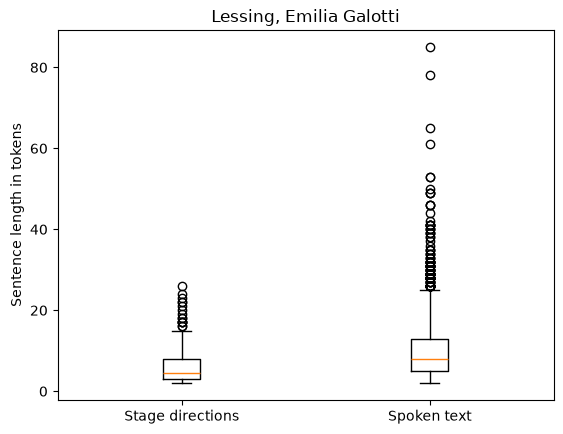

In [9]:
fig, ax = plt.subplots()
ax.boxplot([sd_sentences["tokens"], sp_sentences["tokens"]])
ax.set_xticks([1, 2], ["Stage directions", "Spoken text"])
ax.set_ylabel("Sentence length in tokens")
ax.set_title("Lessing, Emilia Galotti")
plt.show()

## Showcase 3: Plotting network measures for thousands of plays

*D7.1, §4.4*

Connected to the DraCor corpora are services that, following the principle of "method as a microservice", apply specific methods of CLS to the texts of the plays. Their results are available as metrics through the DraCor API. Some of these research-driven functions rely on methods of Social Network Analysis: based on the homogenised TEI structure of the plays, in particular the identification of the speakers, a service builds the network of each play and computes a number of network measures.

Because the metrics of plays from many different corpora can be retrieved through one single API, standardised analyses for comparative literary studies become possible. Trilcke et al. (2024) applied the concept of the "small world" to almost 3,000 plays of European literature. Analysing plays with reference to the small-world concept requires the network measure "average path length" (see the [NetworkX documentation](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.shortest_paths.generic.average_shortest_path_length.html) of this measure).

In D7.1, the average path length of 2,622 plays written between 1500 and 1900 was plotted (Figure 5):

![Average path length of 2,622 plays, 1500–1900](images/d71-fig06-average-path-length.png)

*Figure 5: Average path length of 2,622 plays from the DraCor corpora, 1500–1900 (D7.1, Fig. 06).*

The endpoint `/corpora/{corpusname}/metadata/csv` returns the metadata of all plays of a corpus as a table, including network measures such as `averagePathLength`. We load this table for every corpus on the server. The tables can be read directly with pandas.

In [10]:
corpora = dracor.get_corpora()

tables = []
for corpus in corpora:
    table = pd.read_csv(f"{api_base}/corpora/{corpus.name}/metadata/csv")
    table.insert(0, "corpus", corpus.name)
    tables.append(table)

metadata = pd.concat(tables, ignore_index=True)
print(f"Metadata of {len(metadata):,} plays in {len(corpora)} corpora")

Metadata of 4,924 plays in 24 corpora


DraCor corpora are *living corpora*: plays are added and corrected all the time. The result of this showcase depends on the state of the corpora at the time the data is loaded. The API returns this state as the commit (Git SHA) of each corpus, which we note down along with the date (see Börner and Trilcke 2024 on versioning living corpora):

In [11]:
from datetime import date

corpus_versions = pd.DataFrame(
    [{"corpus": c.name, "title": c.title, "commit": c.commit} for c in corpora]
)
print(f"Retrieved from {api_base} on {date.today().isoformat()}")
corpus_versions

Retrieved from https://dracor.org/api/v1 on 2026-11-17


,corpus,title,commit
0,als,Alsatian Drama Corpus,b37b66e79e4b59cd02434dcfb17e1263080c173c
1,am,American Drama Corpus,57fdc6baa024b17168572452a2bac55070f73f13
2,ar,Argentinian Drama Corpus,28ed008faf2c78789c113cdf8d9452af4f001c6f
3,bash,Bashkir Drama Corpus,6d1cf56195673dc4c7e66971b3a1a95ef4c70402
4,cal,Calderón Drama Corpus,10e64dbceaac65e75db9c7343c09339eee77c617
5,dutch,Dutch Drama Corpus,7b5ade5dd236ff90b44c5c2f1dcd07ce04ac729b
6,eng,English Drama Corpus,16fc318f1ef1bc8a5733aad6f5013b5b665ff91d
7,fre,French Drama Corpus,dc9c2085a9444a959dcf56a07979b03799907f1b
8,ger,German Drama Corpus,4919ac26811d2cde453de6d3ef22d0b6689a3bb1
9,gersh,German Shakespeare Drama Corpus,bf7f0a8a4efd27f9779ff159871bbcf0895ab90c


We filter the plays on [`yearNormalized`](https://dracor.org/doc/faq) to keep those between 1500 and 1900. Plays whose network has no edges (e.g. monologues) have an average path length of 0, and for some plays no network metrics are available; we leave these out, as the plot in D7.1 does:

In [12]:
in_period = metadata[metadata["yearNormalized"].between(1500, 1900)]
plays_1500_1900 = in_period[in_period["averagePathLength"] > 0]
print(f"{len(in_period):,} plays between 1500 and 1900, "
      f"{len(in_period) - len(plays_1500_1900):,} of them without a path length (no edges or no network)")
print(f"{len(plays_1500_1900):,} plays plotted")
plays_1500_1900[["corpus", "name", "yearNormalized", "averagePathLength"]].head()

4,406 plays between 1500 and 1900, 145 of them without a path length (no edges or no network)
4,261 plays plotted


,corpus,name,yearNormalized,averagePathLength
0,als,arnold-der-pfingstmontag,1816.0,1.100000
10,als,greber-d-jumpfer-prinzesse,1899.0,1.090909
11,als,greber-lucie,1896.0,1.285714
12,als,greber-sainte-cecile,1897.0,1.428571
23,als,schneegans-steckelburjer-universite-saaue,1897.0,1.133333


Finally, we plot the average path length of these plays:

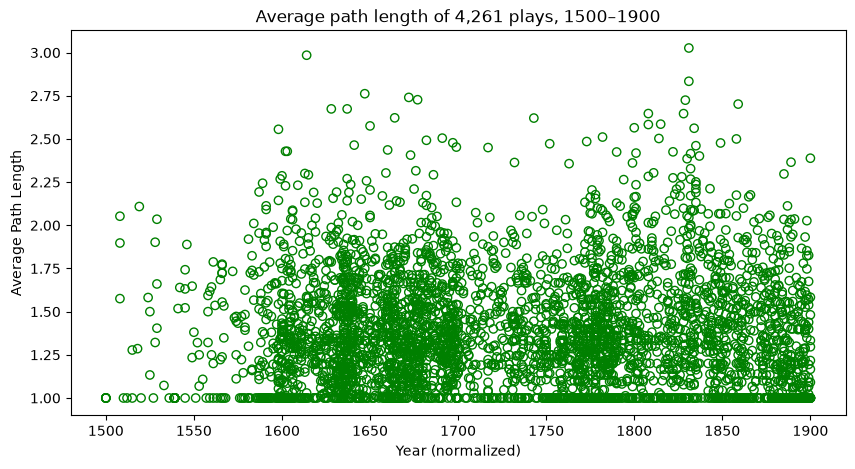

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(plays_1500_1900["yearNormalized"], plays_1500_1900["averagePathLength"],
           facecolors="none", edgecolors="green")
ax.set_xlabel("Year (normalized)")
ax.set_ylabel("Average Path Length")
ax.set_title(f"Average path length of {len(plays_1500_1900):,} plays, 1500–1900")
plt.show()

The number of plays and the plot differ from Figure 5, because the corpora have grown and changed since the report was written. To get exactly the data of a study again, its corpus versions have to be known; this is what the table of commits above is for.

With just a few lines of code, we took a decisive step towards a full "distant reading" study. At the same time, it becomes clear what is still missing from these data, and what an elaborate study would have to provide: the interpretation of the data, which has to work out the meaning of such plots.

## References

Bastian, Mathieu, Sebastien Heymann, and Mathieu Jacomy. 2009. "Gephi: An Open Source Software for Exploring and Manipulating Networks." In *Proceedings of the International AAAI Conference on Web and Social Media* 3 (1): 361–62. [https://gephi.org/publications/gephi-bastian-feb09.pdf](https://gephi.org/publications/gephi-bastian-feb09.pdf).

Börner, Ingo, and Peer Trilcke. 2023. *CLS INFRA D7.1 On Programmable Corpora*. Zenodo. [https://doi.org/10.5281/zenodo.7664964](https://doi.org/10.5281/zenodo.7664964).

Börner, Ingo, and Peer Trilcke. 2024. *CLS INFRA D7.3 On Versioning Living and Programmable Corpora*. Zenodo. [https://doi.org/10.5281/zenodo.11081934](https://doi.org/10.5281/zenodo.11081934).

Hagberg, Aric A., Daniel A. Schult, and Pieter J. Swart. 2008. "Exploring Network Structure, Dynamics, and Function Using NetworkX." In *Proceedings of the 7th Python in Science Conference (SciPy2008)*, edited by Gaël Varoquaux, Travis Vaught, and Jarrod Millman, 11–15. Pasadena, CA.

Moretti, Franco. 2011. *Network Theory, Plot Analysis*. Pamphlets of the Stanford Literary Lab 2. Stanford Literary Lab.

Trilcke, Peer, Christopher Kittel, Nils Reiter, Daria Maximova, and Frank Fischer. 2020. "Opening the Stage: A Quantitative Look at Stage Directions in German Drama." In *DH2020: Book of Abstracts*, edited by Laura Estill and Jennifer Guiliano. [https://dh2020.adho.org/wp-content/uploads/2020/07/337_OpeningtheStageAQuantitativeLookatStageDirectionsinGermanDrama.html](https://dh2020.adho.org/wp-content/uploads/2020/07/337_OpeningtheStageAQuantitativeLookatStageDirectionsinGermanDrama.html).

Trilcke, Peer, Evgeniya Ustinova, Ingo Börner, Frank Fischer, and Carsten Milling. 2024. "Detecting Small Worlds in a Corpus of Thousands of Theater Plays: A DraCor Study in Comparative Literary Network Analysis." In *Computational Drama Analysis: Reflecting Methods and Interpretations*, edited by Melanie Andresen and Nils Reiter. Boston: De Gruyter.

## Use of AI

The update of this notebook to DraCor API v1 and PyDraCor 3 (version 2) was drafted with Claude Code (Anthropic), based on the 2024 version and the instructions of the authors, and reviewed by the authors.

## Version history

The version history of this notebook is documented in [README.md](https://github.com/dracor-org/dracor-notebooks/blob/main/explorecor-showcases/README.md). In the [DraCor Notebooks book](https://dracor-org.github.io/dracor-notebooks/), it follows below.

```{include} README.md
:start-after: "## Version history"
```